# Foundations of Data Science
## Tutorial 2 — The Curse (and Blessing) of Dimensionality

Welcome back! Last week we used Python to *simulate* random variables. Today we use it to **see** geometry that is impossible to picture directly: the geometry of high-dimensional space.

By the end of this notebook you will have empirically verified — by writing the code yourself — three famous results about high dimensions:

1. The **volume of the unit ball** vanishes as $d \to \infty$.
2. Almost all of that vanishing volume sits in a thin **shell at the surface**.
3. To sample a point **uniformly in the ball**, naive ideas fail; the right algorithm is non-obvious.
4. Random unit vectors are **nearly orthogonal**.
5. **Johnson–Lindenstrauss**: you can compress data from $d$ to $O(\log n)$ dimensions and still preserve all pairwise distances.

**How to use this notebook.** Cells marked *`# your code here`* are for you to fill in. After each one we reveal a reference solution. Don't peek before trying — these exercises are how the intuition sticks.


### Setup

Run this cell once. We fix a seed so your plots match the reference.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import gamma

rng = np.random.default_rng(42)

plt.rcParams["figure.figsize"] = (9, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False


## 1. Volume of the unit ball

The volume of the $d$-dimensional unit ball is

$$V_d \;=\; \frac{\pi^{d/2}}{\Gamma\!\left(\tfrac{d}{2}+1\right)}.$$

You may know $V_1 = 2$, $V_2 = \pi$, $V_3 = \tfrac{4}{3}\pi$. The pattern looks like it should keep growing — after all, in dimension $d$ the unit ball *contains* unit balls of every lower dimension.

**Make a prediction first.** Does $V_d$ keep growing? Stay constant? Shrink? At what dimension does it peak?


### Exercise 1.1 — implement and plot $V_d$

Write `ball_volume(d)` using `np.pi` and `scipy.special.gamma`, then plot $V_d$ for $d = 1, \dots, 30$.

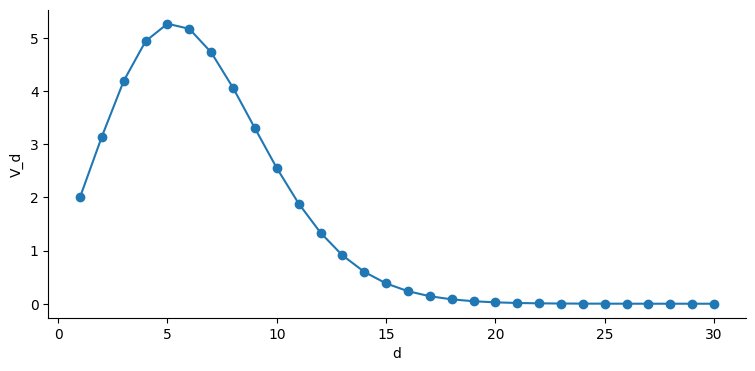

In [2]:
# your code here
def ball_volume(d):
    return np.pi ** (d / 2) / gamma(d / 2 + 1)

dims = np.arange(1, 31)
plt.plot(dims, ball_volume(dims), 'o-')
plt.xlabel("d"); plt.ylabel("V_d")
plt.show()


**Reference solution.** Run this and compare with yours.


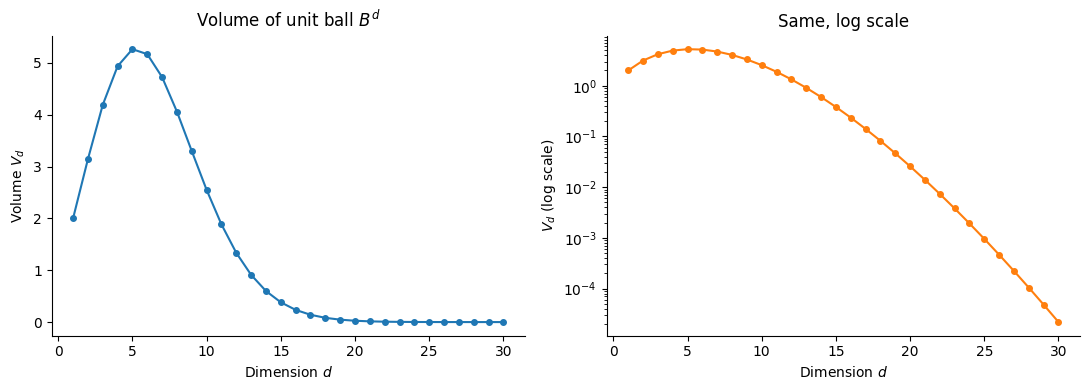

V_d peaks at d = 5  (V = 5.2638)
V_2  = 3.1416    (= π)
V_30 = 2.19e-05  (essentially zero)


In [2]:
def ball_volume(d):
    return np.pi ** (d / 2) / gamma(d / 2 + 1)

dims = np.arange(1, 31)
vols = ball_volume(dims)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(dims, vols, "o-", ms=4)
axes[0].set_xlabel("Dimension $d$")
axes[0].set_ylabel("Volume $V_d$")
axes[0].set_title("Volume of unit ball $B^d$")

axes[1].semilogy(dims, vols, "o-", ms=4, color="tab:orange")
axes[1].set_xlabel("Dimension $d$")
axes[1].set_ylabel("$V_d$ (log scale)")
axes[1].set_title("Same, log scale")
plt.tight_layout(); plt.show()

peak_d = dims[np.argmax(vols)]
print(f"V_d peaks at d = {peak_d}  (V = {ball_volume(peak_d):.4f})")
print(f"V_2  = {ball_volume(2):.4f}    (= π)")
print(f"V_30 = {ball_volume(30):.2e}  (essentially zero)")


**What just happened?** Volume peaks around $d = 5$, then collapses to zero. Above $d \approx 30$ the volume of the *unit* ball is smaller than the volume of one molecule of water in 3-space. The ball is still there — it just doesn't take up much room in the box $[-1,1]^d$.

So where did the volume go? That's Part 2.


## 2. Mass concentrates near the surface — the annulus

Define the **$\varepsilon$-annulus** of the unit ball as the shell

$$A_\varepsilon \;=\; B^d(1) \setminus B^d(1-\varepsilon).$$

Since $V_d(r) = r^d V_d(1)$, the *fraction* of the ball's volume that sits in the $\varepsilon$-annulus is

$$\frac{\operatorname{vol}(A_\varepsilon)}{\operatorname{vol}(B^d)} \;=\; 1 - (1-\varepsilon)^d.$$

This is a nice clean formula — let's see what it predicts for three different choices of $\varepsilon$.


### Exercise 2.1 (i) — fixed $\varepsilon = 1/100$

Write a function `annulus_fraction(d, eps)` that returns $1 - (1-\varepsilon)^d$, then evaluate it for $d = 10, 100, 1000$ with $\varepsilon = 1/100$.

**Predict first.** A 1% shell — surely most of the ball is *inside* the shell, not in it? What does the formula say in $d = 1000$?


In [ ]:
# your code here


**Reference.**


In [4]:
def annulus_fraction(d, eps):
    return 1 - (1 - eps) ** d

for d in [10, 100, 1000]:
    print(f"d = {d:5d}:  vol(A_{{1/100}}) / vol(B^d) = {annulus_fraction(d, 1/100):.4f}")


d =    10:  vol(A_{1/100}) / vol(B^d) = 0.0956
d =   100:  vol(A_{1/100}) / vol(B^d) = 0.6340
d =  1000:  vol(A_{1/100}) / vol(B^d) = 1.0000


At $d = 1000$ a one-percent shell already contains more than 99.99% of the ball. **Volume hugs the surface.**

For estimation, a useful one-line bound: $(1-\varepsilon)^d \le e^{-\varepsilon d}$, so $1 - (1-\varepsilon)^d \ge 1 - e^{-\varepsilon d}$. With $\varepsilon = 1/100$ this gives $1 - e^{-d/100}$, which clears 99% as soon as $d \gtrsim 460$.


### Exercise 2.1 (ii) and (iii) — shrinking shells

Now let the shell *shrink* with the dimension. Compute the annulus fraction for

- $\varepsilon = 1/\sqrt{d}$ (shrinks slowly), and
- $\varepsilon = 1/d^2$ (shrinks fast),

evaluated at $d = 10, 100, 1000$. Predict before running.

> Hint: even though $\varepsilon \to 0$, the exponent $d$ may grow faster. Work out $(1-\varepsilon)^d \approx e^{-\varepsilon d}$ in your head: $\varepsilon = 1/\sqrt d$ gives $e^{-\sqrt d}$ (shrinks!), $\varepsilon = 1/d^2$ gives $e^{-1/d} \to 1$.


In [ ]:
# your code here


**Reference.**


In [7]:
print(f"{'d':>5}  {'1/√d shell':>14}  {'1/d² shell':>14}")
for d in [10, 100, 1000]:
    f1 = annulus_fraction(d, 1 / np.sqrt(d))
    f2 = annulus_fraction(d, 1 / d**2)
    print(f"{d:5d}  {f1:14.6f}  {f2:14.6f}")


    d      1/√d shell      1/d² shell
   10        0.977658        0.095618
  100        0.999973        0.009951
 1000        1.000000        0.001000


- The $1/\sqrt d$-shell keeps capturing essentially *all* the volume — its fraction goes to 1 like $1 - e^{-\sqrt d}$.
- The $1/d^2$-shell becomes too thin to matter — its fraction goes to 0 like $1/d$.

So $1/\sqrt d$ is roughly the *characteristic* shell thickness of a ball in $d$ dimensions. Anything thicker and you have all the mass; anything thinner and you have none.


### Exercise 2.1 (iv) — plot all four functions

Plot $1 - (1-\varepsilon)^d$ as a function of $d$ from $1$ to $100$, for the four choices

$$\varepsilon \in \{ \tfrac{1}{100},\; \tfrac{1}{\sqrt d},\; \tfrac{1}{d^2},\; \tfrac{1}{d} \}.$$

Add a horizontal dashed line at $0.99$.


In [ ]:
# your code here


**Reference.**


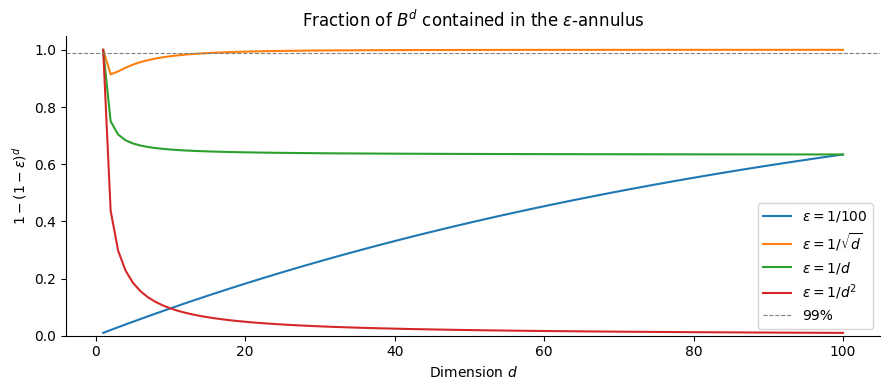

In [8]:
dims = np.arange(1, 101)
curves = {
    r"$\varepsilon = 1/100$":        annulus_fraction(dims, 1/100),
    r"$\varepsilon = 1/\sqrt{d}$":   annulus_fraction(dims, 1/np.sqrt(dims)),
    r"$\varepsilon = 1/d$":          annulus_fraction(dims, 1/dims),
    r"$\varepsilon = 1/d^2$":        annulus_fraction(dims, 1/dims**2),
}

plt.figure()
for label, vals in curves.items():
    plt.plot(dims, vals, label=label)
plt.axhline(0.99, color="gray", linestyle="--", lw=0.8, label="99%")
plt.xlabel("Dimension $d$")
plt.ylabel(r"$1 - (1-\varepsilon)^d$")
plt.title(r"Fraction of $B^d$ contained in the $\varepsilon$-annulus")
plt.legend()
plt.ylim(0, 1.05)
plt.tight_layout(); plt.show()


### Exercise 2.1 (v) — analytic 99% question

For which $\varepsilon$ does the $\varepsilon$-annulus contain at least $99\%$ of $B^d$?

Solve $1 - (1-\varepsilon)^d \ge 0.99$ analytically, *then* implement the threshold and plot it.

> Solving: $(1-\varepsilon)^d \le 0.01$, i.e. $\varepsilon \ge 1 - 0.01^{1/d}$.

> *Asymptotic shortcut.* Using $1 - 0.01^{1/d} \approx -\ln(0.01)/d = \ln(100)/d \approx 4.6/d$, the threshold scales like $\Theta(1/d)$.


In [ ]:
# your code here:
# - implement eps_threshold(d) returning the smallest eps with annulus >= 99%
# - plot it for d = 1..100, alongside the asymptotic ln(100)/d


**Reference.**


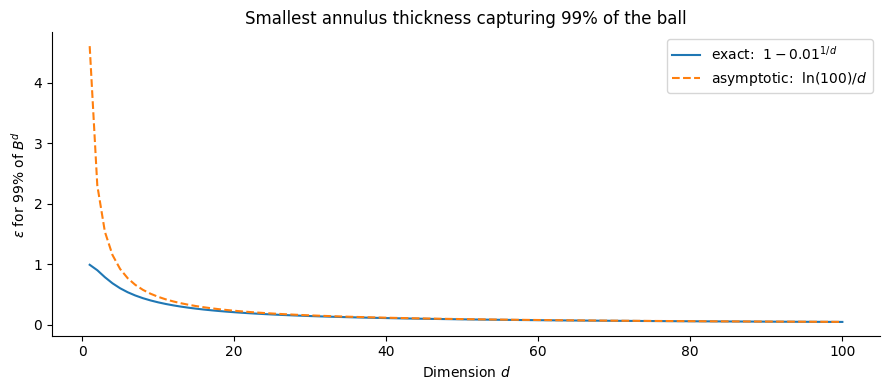

d =    10:  eps* = 0.36904   (≈ ln(100)/d = 0.46052)
d =   100:  eps* = 0.04501   (≈ ln(100)/d = 0.04605)
d =  1000:  eps* = 0.00459   (≈ ln(100)/d = 0.00461)


In [9]:
def eps_threshold(d, target=0.99):
    return 1 - (1 - target) ** (1 / d)

dims = np.arange(1, 101)
exact   = eps_threshold(dims)
asympt  = np.log(100) / dims

plt.figure()
plt.plot(dims, exact,  label=r"exact:  $1 - 0.01^{1/d}$")
plt.plot(dims, asympt, "--", label=r"asymptotic:  $\ln(100)/d$")
plt.xlabel("Dimension $d$")
plt.ylabel(r"$\varepsilon$ for $99\%$ of $B^d$")
plt.title("Smallest annulus thickness capturing 99% of the ball")
plt.legend()
plt.tight_layout(); plt.show()

for d in [10, 100, 1000]:
    print(f"d = {d:5d}:  eps* = {eps_threshold(d):.5f}   (≈ ln(100)/d = {np.log(100)/d:.5f})")


**Take-home.** In dimension $d$, *almost all* of the unit ball is within distance $O(1/d)$ of its surface. The interior is empty in a measure-theoretic sense. This is the first form of the **concentration of measure** phenomenon.


## 3. Sampling a uniformly random point in the ball

> *This used to be Exercise 2.3. It's a great exercise — you'll see why naïve ideas fail.*

We want a routine `sample_uniform_ball(n, d)` that returns $n$ points drawn **uniformly** from the unit ball $B^d \subset \mathbb{R}^d$.

> "Uniform on the ball" means: for any sub-region $R \subseteq B^d$, the probability of landing in $R$ is $\operatorname{vol}(R)/\operatorname{vol}(B^d)$.


### Attempt 1 — rejection from the cube

Sample $x \in [-1, 1]^d$ uniformly and **keep** it iff $\|x\| \le 1$. This works in low $d$. What's the catch?

**Predict.** The ratio $V_d / 2^d$ tells you the acceptance rate. From Part 1, $V_{30} \approx 2 \cdot 10^{-14}$, while $2^{30} \approx 10^9$. So one accept per $\sim 10^{23}$ tries. **Useless beyond $d \approx 10$.**


In [10]:
def sample_by_rejection(n, d, rng, max_tries=10**7):
    accepted = []
    tries = 0
    while len(accepted) < n and tries < max_tries:
        x = rng.uniform(-1, 1, size=d)
        tries += 1
        if np.sum(x * x) <= 1:
            accepted.append(x)
    return np.array(accepted), tries

# Watch the acceptance rate collapse with d
for d in [2, 4, 8, 12]:
    pts, tries = sample_by_rejection(200, d, rng)
    print(f"d = {d:2d}:  needed {tries:7d} tries to get {len(pts):3d} points "
          f"(acceptance ≈ {len(pts)/tries:.2e})")


d =  2:  needed     253 tries to get 200 points (acceptance ≈ 7.91e-01)
d =  4:  needed     665 tries to get 200 points (acceptance ≈ 3.01e-01)
d =  8:  needed   12507 tries to get 200 points (acceptance ≈ 1.60e-02)
d = 12:  needed  582327 tries to get 200 points (acceptance ≈ 3.43e-04)


### Attempt 2 — random direction, random radius (the wrong way)

Maybe: pick a uniformly random *direction* $u$ on the unit sphere, then pick a radius $r$ uniformly in $[0, 1]$, and return $r \cdot u$.

**This is wrong** — and it's the most common mistake. Why?

> *Hint.* In dimension 2, the area of an annulus of radii $[r, r+dr]$ is $\approx 2\pi r \, dr$, not $dr$. In dimension $d$ the volume element is $\propto r^{d-1}\, dr$. A uniform $r$ over-weights the centre.


### Exercise 3.1 — figure out the correct radius distribution

For a point uniform in $B^d$, what is the probability density of its radius $R = \|X\|$?

Find the density $f_R(r)$ for $r \in [0, 1]$. Then, given a uniform $U \in [0, 1]$, what transformation of $U$ has the right radius distribution?

> Pen-and-paper hint. $\Pr[R \le r] = V_d(r)/V_d(1) = r^d$, so $f_R(r) = d r^{d-1}$. Inverse-CDF: if $U \sim \mathcal{U}[0,1]$ then $R = U^{1/d}$ has the right distribution.


### Attempt 3 — direction + correct radius (the right way)

The clean recipe:

1. Sample direction $u$ uniformly on the unit sphere $S^{d-1}$. *Trick:* draw $g \sim \mathcal{N}(0, I_d)$ and set $u = g/\|g\|$. Gaussians are isotropic, so $u$ is uniform on the sphere.
2. Sample $U \sim \mathcal{U}[0,1]$ and set $r = U^{1/d}$.
3. Return $r u$.

### Exercise 3.2 — implement `sample_uniform_ball`

Write the function. It should take `(n, d, rng)` and return an `(n, d)` array.


In [ ]:
# your code here
# def sample_uniform_ball(n, d, rng):
#     ...


**Reference.**


In [11]:
def sample_uniform_ball(n, d, rng):
    # Step 1: uniform direction on the sphere via a normalised Gaussian
    g = rng.standard_normal((n, d))
    u = g / np.linalg.norm(g, axis=1, keepdims=True)
    # Step 2: radius with the correct r^{d-1} density
    r = rng.uniform(0, 1, (n, 1)) ** (1 / d)
    return r * u

# Quick sanity: in d=2 the squared radius should be uniform (since R^2 has CDF r^2).
pts = sample_uniform_ball(20000, 2, rng)
sq = (pts ** 2).sum(axis=1)
print(f"d=2: mean of R² = {sq.mean():.3f} (theory: 1/2 = {1/2:.3f})")
print(f"d=2: max ‖x‖    = {np.sqrt(sq).max():.3f} (must be ≤ 1)")


d=2: mean of R² = 0.496 (theory: 1/2 = 0.500)
d=2: max ‖x‖    = 1.000 (must be ≤ 1)


### Exercise 3.3 — plot $1\,200$ points in $d = 2$

Sample 1\,200 points and scatter-plot them. Add the unit circle for reference.


In [ ]:
# your code here


**Reference.**


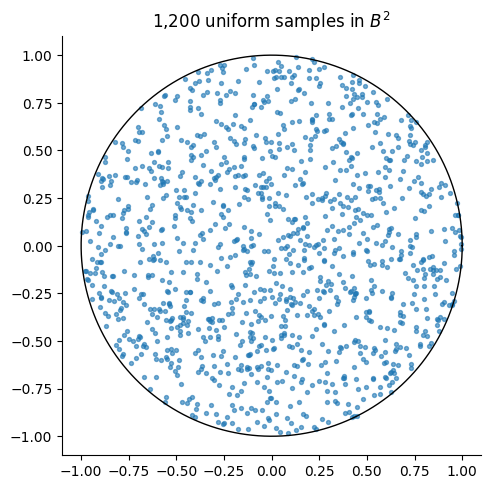

In [12]:
pts = sample_uniform_ball(1200, 2, rng)

theta = np.linspace(0, 2 * np.pi, 200)
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(pts[:, 0], pts[:, 1], s=8, alpha=0.6)
ax.plot(np.cos(theta), np.sin(theta), "k-", lw=1)
ax.set_aspect("equal")
ax.set_title("1,200 uniform samples in $B^2$")
plt.tight_layout(); plt.show()


### Exercise 3.4 (bonus) — same in $d = 3$

Use `mpl_toolkits.mplot3d` (or just `plt.figure().add_subplot(projection='3d')`).


In [ ]:
# your code here


**Reference.**


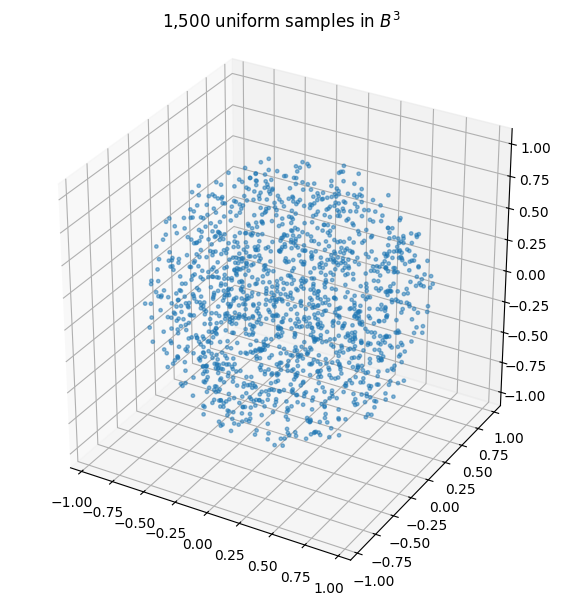

In [13]:
pts3 = sample_uniform_ball(1500, 3, rng)

fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(projection="3d")
ax.scatter(pts3[:, 0], pts3[:, 1], pts3[:, 2], s=6, alpha=0.5)
ax.set_box_aspect((1, 1, 1))
ax.set_title("1,500 uniform samples in $B^3$")
plt.tight_layout(); plt.show()


### Sanity check — does the sampler agree with Part 2?

Use your sampler to **empirically** confirm the annulus theorem: in $d = 50$, what fraction of points land in the outer $\varepsilon = 0.05$ shell?


In [ ]:
# your code here


**Reference.**


In [14]:
d, eps = 50, 0.05
pts = sample_uniform_ball(20000, d, rng)
norms = np.linalg.norm(pts, axis=1)
empirical = np.mean(norms >= 1 - eps)
predicted = 1 - (1 - eps) ** d
print(f"empirical fraction in shell : {empirical:.4f}")
print(f"theory  1 - (1-eps)^d       : {predicted:.4f}")


empirical fraction in shell : 0.9232
theory  1 - (1-eps)^d       : 0.9231


## 4. Mass concentrates near the equator

Pick *any* unit vector $u$ — call it the north pole. For $X$ uniform in $B^d$, the projection $X \cdot u$ measures how far north $X$ is. The theorem from class:

$$\Pr\bigl[\,|X \cdot u| \ge \varepsilon\,\bigr] \;\le\; 2 e^{-d \varepsilon^2 / 2}.$$

In words: in high dimensions essentially all of the ball lies in a thin equatorial slab, **whichever** direction you call "up".

### Exercise 4.1 — visualise it

Sample $5\,000$ points uniformly in $B^d$ for $d \in \{2, 10, 100\}$, project onto $e_1$, and histogram the result. What changes with $d$?


In [ ]:
# your code here


**Reference.**


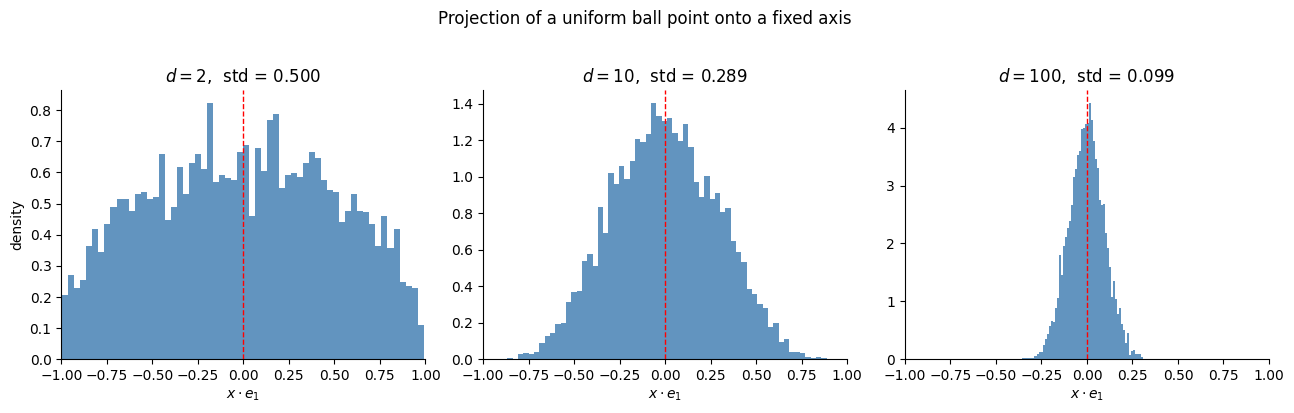

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, d in zip(axes, [2, 10, 100]):
    pts = sample_uniform_ball(5000, d, rng)
    proj = pts[:, 0]                        # projection onto e_1
    ax.hist(proj, bins=60, density=True, color="steelblue", alpha=0.85)
    ax.axvline(0, color="red", ls="--", lw=1)
    ax.set_xlim(-1, 1)
    ax.set_xlabel(r"$x \cdot e_1$")
    ax.set_title(f"$d = {d}$,  std = {proj.std():.3f}")
axes[0].set_ylabel("density")
plt.suptitle("Projection of a uniform ball point onto a fixed axis", y=1.02)
plt.tight_layout(); plt.show()


### Exercise 4.2 — empirical vs. theoretical bound

Estimate $\Pr[|X \cdot u| \ge 0.2]$ for several $d$ and overlay it with the bound $2 e^{-d\varepsilon^2 / 2}$.


In [ ]:
# your code here


**Reference.**


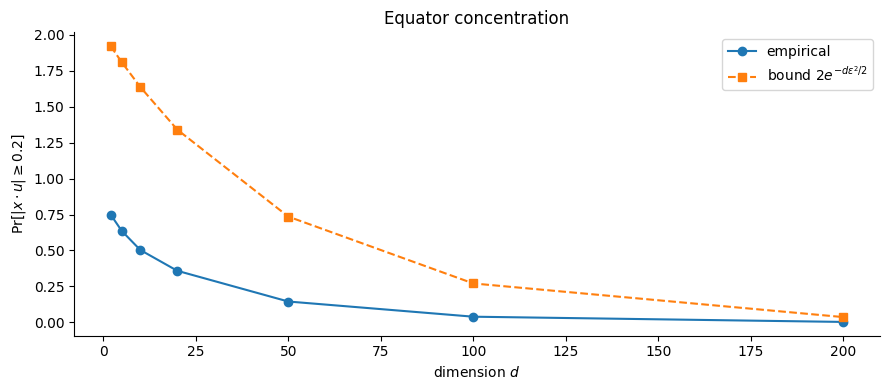

In [16]:
eps = 0.2
ds = [2, 5, 10, 20, 50, 100, 200]
emp, thy = [], []
for d in ds:
    pts = sample_uniform_ball(5000, d, rng)
    emp.append(np.mean(np.abs(pts[:, 0]) >= eps))
    thy.append(2 * np.exp(-d * eps**2 / 2))

plt.figure()
plt.plot(ds, emp, "o-",  label="empirical")
plt.plot(ds, thy, "s--", label=r"bound $2e^{-d\varepsilon^2/2}$")
plt.xlabel("dimension $d$")
plt.ylabel(rf"$\Pr[|x\cdot u|\geq{eps}]$")
plt.title("Equator concentration")
plt.legend(); plt.tight_layout(); plt.show()


## 5. Random unit vectors are nearly orthogonal

Pick two independent unit vectors $x, y$ in $\mathbb{R}^d$. The dot product $x \cdot y$ has mean 0 and standard deviation $1/\sqrt d$.

### Exercise 5.1 — verify

For $d \in \{2, 10, 1000\}$, draw 500 pairs and histogram their dot products. Confirm the standard deviation matches $1/\sqrt d$.


In [ ]:
# your code here


**Reference.**


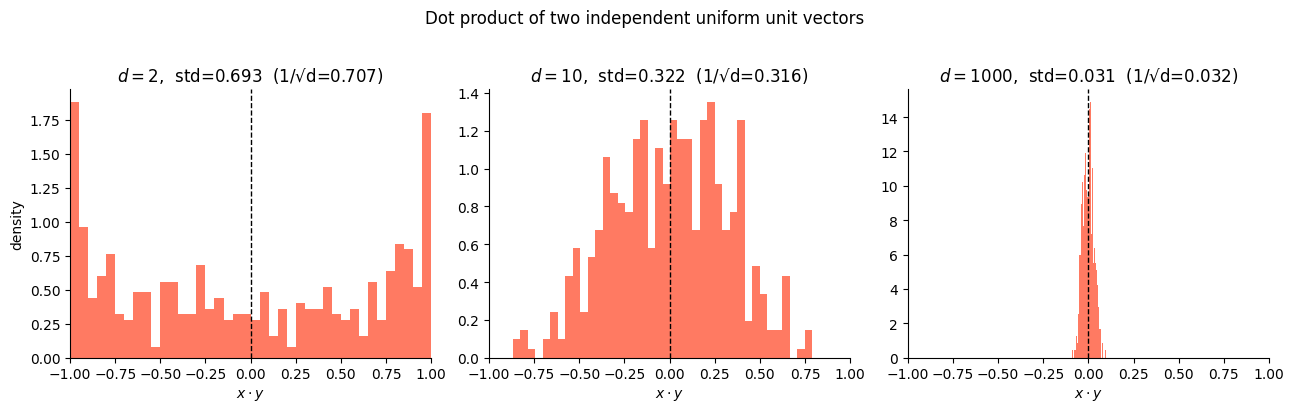

In [17]:
def sample_unit_sphere(n, d, rng):
    g = rng.standard_normal((n, d))
    return g / np.linalg.norm(g, axis=1, keepdims=True)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, d in zip(axes, [2, 10, 1000]):
    a = sample_unit_sphere(500, d, rng)
    b = sample_unit_sphere(500, d, rng)
    dots = np.sum(a * b, axis=1)
    ax.hist(dots, bins=40, density=True, color="tomato", alpha=0.85)
    ax.axvline(0, color="black", ls="--", lw=1)
    ax.set_xlim(-1, 1)
    ax.set_xlabel(r"$x \cdot y$")
    ax.set_title(f"$d={d}$,  std={dots.std():.3f}  (1/√d={1/np.sqrt(d):.3f})")
axes[0].set_ylabel("density")
plt.suptitle("Dot product of two independent uniform unit vectors", y=1.02)
plt.tight_layout(); plt.show()


**Consequence.** You can pack *exponentially many* nearly-orthogonal directions into $\mathbb{R}^d$. This is what powers many random embeddings, including the next section.


## 6. Johnson–Lindenstrauss: compress without losing distances

> *Optional / preview. The full proof is in Chapter 2.7 of Blum–Hopcroft–Kannan.*

**Lemma.** For any $n$ points in $\mathbb{R}^d$ and any $\varepsilon \in (0,1)$, there is a linear map $f: \mathbb{R}^d \to \mathbb{R}^k$ with $k = O(\log n / \varepsilon^2)$ such that, simultaneously for all pairs,

$$(1-\varepsilon)\|x_i - x_j\|^2 \;\le\; \|f(x_i) - f(x_j)\|^2 \;\le\; (1+\varepsilon)\|x_i - x_j\|^2.$$

The map is just a random Gaussian matrix scaled by $1/\sqrt{k}$. Let's try it on the sklearn digits dataset.


In [18]:
from sklearn.datasets import load_digits

digits = load_digits()
X = digits.data.astype(float)         # 1797 points in R^64
n, d_orig = X.shape
print(f"{n} points in R^{d_orig}")


1797 points in R^64


### Exercise 6.1 — implement and test the JL projection

Write `jl_project(X, k, rng)` returning $X R$ with $R \in \mathbb{R}^{d \times k}$ Gaussian and scaled by $1/\sqrt k$. Then for several $k$ measure the mean squared-distance ratio between projected and original pairs.


In [ ]:
# your code here


**Reference.**


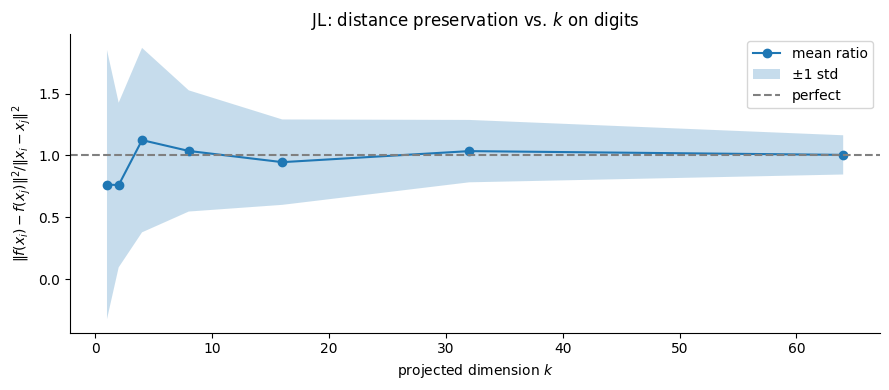

In [19]:
def jl_project(X, k, rng):
    d = X.shape[1]
    R = rng.standard_normal((d, k)) / np.sqrt(k)
    return X @ R

n_pairs = 4000
ks = [1, 2, 4, 8, 16, 32, 64]
mean_ratio = []
std_ratio  = []
for k in ks:
    Xk = jl_project(X, k, rng)
    idx = rng.integers(0, n, size=(n_pairs, 2))
    idx[idx[:, 0] == idx[:, 1], 1] = (idx[idx[:, 0] == idx[:, 1], 1] + 1) % n
    do = np.linalg.norm(X[idx[:, 0]]  - X[idx[:, 1]],  axis=1)
    dp = np.linalg.norm(Xk[idx[:, 0]] - Xk[idx[:, 1]], axis=1)
    r  = (dp ** 2) / (do ** 2 + 1e-12)
    mean_ratio.append(r.mean()); std_ratio.append(r.std())

mean_ratio = np.array(mean_ratio); std_ratio = np.array(std_ratio)
plt.figure()
plt.plot(ks, mean_ratio, "o-", label="mean ratio")
plt.fill_between(ks, mean_ratio - std_ratio, mean_ratio + std_ratio,
                 alpha=0.25, label="±1 std")
plt.axhline(1.0, color="gray", ls="--", label="perfect")
plt.xlabel("projected dimension $k$")
plt.ylabel(r"$\|f(x_i)-f(x_j)\|^2 / \|x_i-x_j\|^2$")
plt.title("JL: distance preservation vs. $k$ on digits")
plt.legend(); plt.tight_layout(); plt.show()


The mean ratio is $\approx 1$ already at small $k$ (the projection is **unbiased**). What shrinks with $k$ is the *spread*. With $k$ large enough, the spread is small enough that *every* pair lands in the $[1-\varepsilon, 1+\varepsilon]$ window — that's the lemma.


## Wrap up

Today you implemented, with your own hands:

- The volume of the unit ball — and watched it collapse.
- The annulus formula $1 - (1-\varepsilon)^d$ for four shell thicknesses
- A correct uniform sampler for the ball, plus the obligatory failed attempts.
- Empirical demonstrations of equator concentration and near-orthogonality of random vectors.
- A JL random projection of a real dataset.

**For the homework (Sheet 2):** the remaining exercises are 2.1 *Random exit* (analytic — geometric distribution and expected runtime) and 2.2 *Fitting a spherical Gaussian to data*. The simulation and plotting techniques from today (especially `sample_uniform_ball` and the histograms in §4) are exactly what you need for 2.2.

Have fun, and ask in the forum if anything is unclear!
